[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/moiz-lakkadkutta/flyconn-course/blob/main/notebooks/02_who_talks_to_whom.ipynb)

# 2. Who talks to whom

Notebook 1 met the neurons. Now add the **connections**: for each pair of neurons, how many
synapses the first makes onto the second.

**Learning goals.** By the end of this notebook you can

1. read an edge list (`pre`, `post`, `weight`) and list a neuron's input and output partners;
2. turn synapse counts into **input fractions**, which compare better across neurons;
3. group partners by cell type;
4. show that a **synapse threshold** changes the answer to "who is connected?", and by how much.

**Time:** about 45 minutes. **You need:** notebook 1.

In [1]:
# @title Setup: run this cell first { display-mode: "form" }
import sys
import urllib.request
from pathlib import Path

if "google.colab" in sys.modules:
    %pip install -q flyconn==0.4.0 matplotlib
    pass
if not Path("course_utils.py").exists():
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/moiz-lakkadkutta/flyconn-course/main/notebooks/course_utils.py",
        "course_utils.py",
    )

import matplotlib.pyplot as plt
import pandas as pd

import course_utils as cu

pd.set_option("display.max_rows", 20)
store = cu.open_store()
neurons = store.neurons().set_index("neuron_id", drop=False)

## 1. The edge list

Each row is one connection: `pre` (the sending neuron) makes `weight` synapses onto `post`
(the receiving neuron). Synapses were detected automatically in the EM images and kept when
the detector's confidence was at least 0.5. Even the "raw" data has already passed one
threshold.

In [2]:
edges = store.edges()
print(f"{len(edges):,} edges, {edges['weight'].sum():,} synapses")
edges.head()

502,095 edges, 3,878,833 synapses


,pre,post,weight
0,10001,10440,1
1,10002,10135,1
2,10002,10205,1
3,10002,10863,15
4,10002,10895,1


> **About this subset.** It holds every connection of the focus neurons: `LB3*`, `MN9`,
> everything `LB3*` talks to and everything that talks to `MN9`. Other neurons appear only as
> their partners, so their own partner lists here are incomplete. The `focus` column marks
> which neurons are complete.

## 2. Most connections are tiny

How many synapses does a typical connection have?

median weight: 2 synapses
edges with 1-2 synapses: 56% of edges, carrying 9% of all synapses


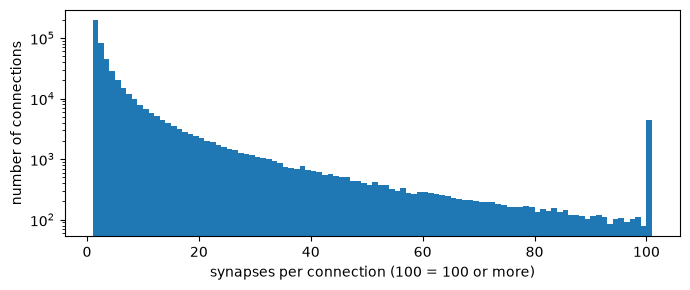

In [3]:
w = edges["weight"]
print(f"median weight: {w.median():.0f} synapses")
print(
    f"edges with 1-2 synapses: {(w <= 2).mean():.0%} of edges, "
    f"carrying {w[w <= 2].sum() / w.sum():.0%} of all synapses"
)

ax = w.clip(upper=100).plot.hist(bins=range(1, 102), log=True, figsize=(7, 3))
ax.set_xlabel("synapses per connection (100 = 100 or more)")
ax.set_ylabel("number of connections")
plt.tight_layout()
assert (w <= 2).mean() > 0.5 and w[w <= 2].sum() / w.sum() < 0.1  # the claims in the text below

More than half of all connections have one or two synapses, yet together they carry fewer than
one synapse in ten. Are they real? Some are certainly detection errors or chance contacts;
others may matter. A common response is a **threshold**: ignore connections with fewer than
*k* synapses (often *k* = 5). The rest of this notebook asks what that choice does.

## 3. Who talks to MN9?

Take the left `MN9` and list its inputs. `store.edges(post=[...])` returns the edges *onto*
the given neurons; `pre=[...]` returns the edges *from* them.

In [4]:
mn9 = neurons.loc[neurons["cell_type"] == "MN9"].sort_values("input_synapses_total")
mn9_big = int(mn9["neuron_id"].iloc[-1])  # the MN9 with more inputs
inputs = store.edges(post=[mn9_big]).join(
    neurons[["cell_type", "super_class", "nt_pred"]], on="pre"
)
inputs = inputs.sort_values("weight", ascending=False)
print(f"MN9 {mn9_big}: {len(inputs)} input neurons")
inputs.head(10)

MN9 10331: 278 input neurons


,pre,post,weight,cell_type,super_class,nt_pred
24,10833,10331,464,DNge062,descending,acetylcholine
28,10881,10331,359,GNG120,central_brain_intrinsic,acetylcholine
98,13754,10331,357,GNG130,central_brain_intrinsic,gaba
77,12851,10331,351,GNG095,central_brain_intrinsic,gaba
166,26764,10331,348,GNG108,central_brain_intrinsic,acetylcholine
248,523590,10331,266,GNG015,central_brain_intrinsic,gaba
25,10849,10331,241,GNG117,central_brain_intrinsic,acetylcholine
220,513655,10331,214,GNG180,central_brain_intrinsic,gaba
119,14891,10331,198,GNG234,central_brain_intrinsic,acetylcholine
147,17782,10331,187,GNG184,central_brain_intrinsic,gaba


### Input fractions

Is 300 synapses a lot? That depends on the receiver. A neuron with 600 inputs in total is
dominated by such a partner; one with 60,000 barely notices it. Dividing by the receiver's
total input gives the **input fraction**, a better measure of influence.

`input_synapses_total` counts every synapse onto the neuron, including from small fragments
that were never joined into a whole neuron. So fractions computed this way never add up to 1.

In [5]:
total = neurons.loc[mn9_big, "input_synapses_total"]
inputs["fraction"] = inputs["weight"] / total
print(f"total inputs: {total:,}; from whole neurons: {inputs['weight'].sum() / total:.0%}")
inputs[["pre", "cell_type", "weight", "fraction", "nt_pred"]].head(10)

total inputs: 6,358; from whole neurons: 95%


,pre,cell_type,weight,fraction,nt_pred
24,10833,DNge062,464,0.072979,acetylcholine
28,10881,GNG120,359,0.056464,acetylcholine
98,13754,GNG130,357,0.056150,gaba
77,12851,GNG095,351,0.055206,gaba
166,26764,GNG108,348,0.054734,acetylcholine
248,523590,GNG015,266,0.041837,gaba
25,10849,GNG117,241,0.037905,acetylcholine
220,513655,GNG180,214,0.033658,gaba
119,14891,GNG234,198,0.031142,acetylcholine
147,17782,GNG184,187,0.029412,gaba


### Group by cell type

Neurons of one type usually act together, so add up the fractions per type.

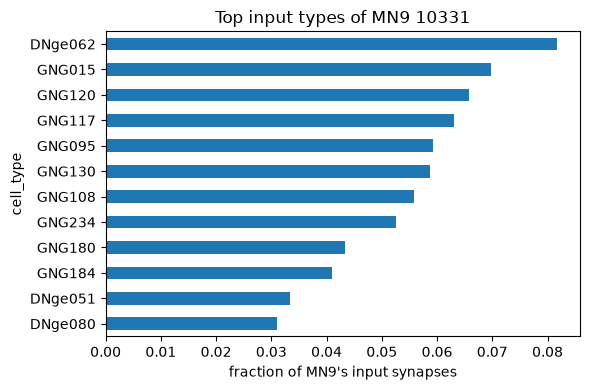

In [6]:
by_type = inputs.groupby("cell_type")["fraction"].sum().sort_values(ascending=False)
ax = by_type.head(12).iloc[::-1].plot.barh(figsize=(6, 4))
ax.set_xlabel("fraction of MN9's input synapses")
ax.set_title(f"Top input types of MN9 {mn9_big}")
plt.tight_layout()

Most top inputs are `GNG*` neurons, in the gnathal ganglia, the region that controls the
mouthparts. `DNge*` are descending neurons.

Each input also has a transmitter label (predicted unless `nt_known` is filled; see notebook
1). Treating acetylcholine as excitatory and GABA
and glutamate as inhibitory (a common assumption in the fly; glutamate can excite as well),
what share of MN9's input is predicted inhibitory?

In [7]:
inhibitory = inputs["nt_pred"].isin(["gaba", "glutamate", "histamine"])
print(
    f"predicted inhibitory: {inputs.loc[inhibitory, 'fraction'].sum():.0%} of input synapses "
    f"(sign from predicted NT)"
)
print(cu.PREDICTED_NT)

predicted inhibitory: 46% of input synapses (sign from predicted NT)
NT = predicted by a classifier from EM images, not measured.


## 4. Thresholds change answers

Now apply thresholds of 1, 2, 3, 5, 10 and 20 synapses to MN9's inputs. Count the input
neurons that survive and the fraction of synapses kept.

In [8]:
def threshold_table(e: pd.DataFrame, thresholds=(1, 2, 3, 5, 10, 20)) -> pd.DataFrame:
    rows = []
    for k in thresholds:
        kept = e[e["weight"] >= k]
        rows.append(
            {
                "threshold": k,
                "partners": len(kept),
                "synapses_kept": kept["weight"].sum() / e["weight"].sum(),
            }
        )
    return pd.DataFrame(rows).set_index("threshold")


threshold_table(inputs)

,partners,synapses_kept
threshold,,
1,278,1.000000
2,167,0.981537
3,133,0.970226
5,93,0.947937
10,60,0.912342
20,47,0.881404


Raising the threshold removes many *partners* but few *synapses*: weak partners are numerous
but small. Does that hold for every neuron? Compare the two `MN9`s.

,MN9 10331 (left),MN9 16949 (right)
threshold,,
1,1.000000,1.000000
2,0.981537,0.872302
3,0.970226,0.785971
5,0.947937,0.694245
10,0.912342,0.570144
20,0.881404,0.343525


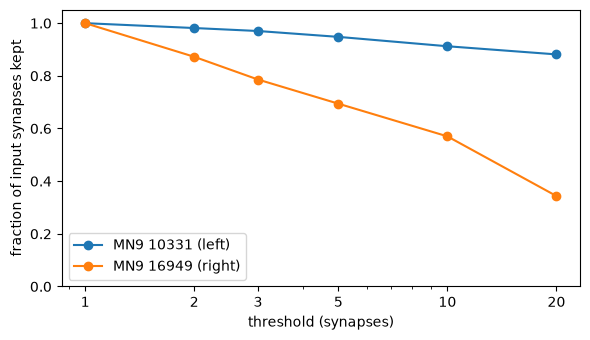

In [9]:
mn9_small = int(mn9["neuron_id"].iloc[0])
both = {}
for nid in (mn9_big, mn9_small):
    t = threshold_table(store.edges(post=[nid]))
    both[f"MN9 {nid} ({neurons.loc[nid, 'side']})"] = t["synapses_kept"]
both = pd.DataFrame(both)
ax = both.plot(marker="o", figsize=(6, 3.5))
ax.set_xscale("log")
ax.set_xticks(both.index, labels=both.index)
ax.set_xlabel("threshold (synapses)")
ax.set_ylabel("fraction of input synapses kept")
ax.set_ylim(0, 1.05)
plt.tight_layout()
both

The threshold that keeps most of one MN9's input throws away much of the other's. A single
global threshold treats neurons unequally; a neuron with few, weak inputs (whatever the
reason) loses the most.

### The same question at the scale of a cell type

Who do the `LB3*` taste neurons talk to? Count partner neurons and partner *types* under each
threshold.

In [10]:
lb3_ids = neurons.index[neurons["cell_type"].fillna("").str.startswith("LB3")]
out = store.edges(pre=lb3_ids).join(neurons[["cell_type"]], on="post")
rows = []
for k in (1, 3, 5, 10):
    kept = out[out["weight"] >= k]
    rows.append(
        {
            "threshold": k,
            "partner_neurons": kept["post"].nunique(),
            "partner_types": kept["cell_type"].nunique(),
            "synapses_kept": kept["weight"].sum() / out["weight"].sum(),
        }
    )
lb3_table = pd.DataFrame(rows).set_index("threshold")
assert lb3_table.loc[10, "partner_types"] < lb3_table.loc[1, "partner_types"] / 5  # text below
lb3_table

,partner_neurons,partner_types,synapses_kept
threshold,,,
1,645,303,1.000000
3,320,148,0.865882
5,231,99,0.763471
10,135,54,0.577266


At threshold 10, the list of partner types the taste neurons talk to is less than a fifth of
the list at threshold 1. Any claim like "LB3 neurons connect to *N* cell types" is only
meaningful with its threshold attached.

One more surprise: are the taste neurons connected to MN9 directly?

In [11]:
direct = store.edges(pre=lb3_ids, post=mn9["neuron_id"].tolist())
print(f"direct LB3* -> MN9 edges at any threshold: {len(direct)}")

direct LB3* -> MN9 edges at any threshold: 0


None. The taste signal must pass through other neurons on its way to the motor neuron. Finding
those routes, and asking how stable they are under different thresholds, is notebook 3.

## 5. The same thing with flyconn

The pandas above is what flyconn does inside. `ConnectivityMatrix` builds a sparse matrix from
a store under a threshold, and `input_normalized()` gives input fractions. Every result
records its settings in `provenance`.

In [12]:
from flyconn.graph import ConnectivityMatrix

m5 = ConnectivityMatrix.from_store(store, min_weight=5)
frac = m5.input_normalized()
col = frac[:, m5.index_of([mn9_big])[0]].toarray().ravel()
print(
    f"MN9 {mn9_big}: {(col > 0).sum()} input neurons at min_weight 5, "
    f"summed fraction {col.sum():.2f}"
)
{k: m5.provenance[k] for k in ("dataset", "min_weight", "sign_policy", "n_neurons", "n_edges")}

MN9 10331: 93 input neurons at min_weight 5, summed fraction 0.90


{'dataset': 'malecns@1.0',
 'min_weight': 5,
 'sign_policy': 'argmax',
 'n_neurons': 46108,
 'n_edges': 149242}

## Exercises

**Exercise 1.** At threshold 5, how many `LB3*` neurons have at least one partner of type
`GNG232`? And at threshold 1?

In [13]:
# your code here

In [14]:
# @title Solution 1 { display-mode: "form" }
gng232 = out[out["cell_type"] == "GNG232"]
for k in (1, 5):
    print(k, gng232.loc[gng232["weight"] >= k, "pre"].nunique(), "LB3* neurons")

1 57 LB3* neurons
5 34 LB3* neurons


**Exercise 2.** Rank MN9's input *types* (left MN9, the one with more inputs) by summed
fraction at threshold 1 and at threshold 20. Do the top five change? Which type moves most?

In [15]:
# your code here

In [16]:
# @title Solution 2 { display-mode: "form" }
rank = {}
for k in (1, 20):
    kept = inputs[inputs["weight"] >= k]
    rank[k] = kept.groupby("cell_type")["fraction"].sum().rank(ascending=False)
rank = pd.DataFrame(rank).sort_values(1)
rank["moved"] = rank[20] - rank[1]
print(rank.head(5))
print("largest move among the top 20:")
print(rank.head(20).sort_values("moved", key=abs, ascending=False).head(3))
print(
    "The top five do not move: strong partners survive any threshold. Only the weak tail "
    "reshuffles, so a threshold matters most for claims about *how many* partners, less for "
    "*which are the strongest*."
)

             1   20  moved
cell_type                 
DNge062    1.0  1.0    0.0
GNG015     2.0  2.0    0.0
GNG120     3.0  3.0    0.0
GNG117     4.0  4.0    0.0
GNG095     5.0  5.0    0.0
largest move among the top 20:
              1    20  moved
cell_type                   
GNG027     19.5  24.0    4.5
GNG537     19.5  18.0   -1.5
GNG159     18.0  19.0    1.0
The top five do not move: strong partners survive any threshold. Only the weak tail reshuffles, so a threshold matters most for claims about *how many* partners, less for *which are the strongest*.


**Exercise 3 (discussion).** Researcher A says "MN9 has 278 inputs"; researcher B says "MN9
has 93 inputs". Both used this dataset. Write two sentences explaining how both can be right,
and what each should have reported alongside the number.

In [17]:
# @title Solution 3 { display-mode: "form" }
for k in (1, 5):
    print(f"threshold {k}: {(inputs['weight'] >= k).sum()} input neurons")
assert [(inputs["weight"] >= k).sum() for k in (1, 5)] == [278, 93]  # numbers in the question
print(
    "Both counted MN9's input neurons, at different synapse thresholds (1 vs 5). "
    "Each should report the threshold, the dataset version and which MN9 (there are two)."
)

threshold 1: 278 input neurons
threshold 5: 93 input neurons
Both counted MN9's input neurons, at different synapse thresholds (1 vs 5). Each should report the threshold, the dataset version and which MN9 (there are two).


## Summary

- An edge list says who makes how many synapses onto whom; input fractions put counts in
  context.
- Most connections are tiny, and a threshold removes many partners but few synapses, unevenly
  across neurons.
- Always report the threshold (and dataset version) with a connectivity claim.

**Go further (grad level).** Rebuild `threshold_table` with `ConnectivityMatrix.from_store` for
several `min_weight` values and compare the *set* of top-10 input types with a Jaccard index.
How fast does it stabilise?

**Next:** notebook 3, *Pathways*: routes from taste neurons to MN9.

*Data: MaleCNS v1.0, Berg et al. 2026, Cell, doi:10.1016/j.cell.2026.08.015 (CC BY 4.0), via
[flyconn](https://github.com/moiz-lakkadkutta/flyconn). Course text CC BY 4.0, code
Apache-2.0.*